# E-commerce Sales EDA — Superstore Dataset
**Kate Pogrebnyakova | Data Scientist**

**Business question:** A regional sales manager has 4 years of order data (~10,000 transactions across the US).
Which segments, categories, and regions are growing, which are struggling, and what should the business do next?

---
## Table of Contents
1. [Setup & Data Loading](#1-setup--data-loading)
2. [Feature Engineering](#2-feature-engineering)
3. [EDA Overview](#3-eda-overview)
4. [C1 — Quarterly Sales & Profit Trend](#c1--quarterly-sales--profit-trend)
5. [C2 — Profit Margin by Category](#c2--profit-margin-by-category)
6. [C3 — Sales by Region × Segment](#c3--sales-by-region--segment)
7. [C4 — Discount vs Profit (Key Insight)](#c4--discount-vs-profit-key-insight)
8. [C5 — Sub-Category Profitability](#c5--sub-category-profitability)
9. [C6 — Customer Segment Comparison](#c6--customer-segment-comparison)
10. [C7 — Shipping Mode Analysis](#c7--shipping-mode-analysis)
11. [C9 — Monthly Seasonality](#c9--monthly-seasonality)
12. [C10 — Customer Cohort Retention](#c10--customer-cohort-retention)
13. [Discount Threshold Analysis](#discount-threshold-analysis)
14. [Key Findings & Recommendations](#key-findings--recommendations)


## 1. Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import os

# ── Styling ──────────────────────────────────────────────────────────────────
sns.set_style("whitegrid")
plt.rcParams.update({
    'figure.figsize': (11, 5),
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
})

NAVY  = '#1a3a5c'
TEAL  = '#00897b'
CORAL = '#e64a19'
GREY  = '#78909c'
LGOLD = '#f9a825'

os.makedirs('../outputs/plots', exist_ok=True)

def save(name):
    plt.savefig(f'../outputs/plots/{name}.png', dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close()


In [2]:
df_raw = pd.read_csv('../data/raw/Sample - Superstore.csv', encoding='latin-1')

df_raw['Order Date'] = pd.to_datetime(df_raw['Order Date'])
df_raw['Ship Date']  = pd.to_datetime(df_raw['Ship Date'])

print(f"Shape: {df_raw.shape}")
print(f"Date range: {df_raw['Order Date'].min().date()} → {df_raw['Order Date'].max().date()}")
print(f"Missing values: {df_raw.isnull().sum().sum()}")
df_raw.head(3)


Shape: (9994, 21)
Date range: 2014-01-03 → 2017-12-30
Missing values: 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714


## 2. Feature Engineering

In [3]:
df = df_raw.copy()

# Profitability
df['Profit Margin'] = df['Profit'] / df['Sales']

# Shipping speed
df['Ship Days'] = (df['Ship Date'] - df['Order Date']).dt.days

# Time dimensions
df['Year']      = df['Order Date'].dt.year
df['Month']     = df['Order Date'].dt.month
df['Quarter']   = df['Order Date'].dt.to_period('Q').astype(str)
df['YearMonth'] = df['Order Date'].dt.to_period('M').astype(str)

# Cohort: year of customer's first order
first_order = df.groupby('Customer ID')['Year'].min().rename('Cohort Year')
df = df.join(first_order, on='Customer ID')

print("New columns added:", ['Profit Margin','Ship Days','Year','Month','Quarter','YearMonth','Cohort Year'])


New columns added: ['Profit Margin', 'Ship Days', 'Year', 'Month', 'Quarter', 'YearMonth', 'Cohort Year']


## 3. EDA Overview

Top-line metrics before diving into charts.

In [4]:
total_sales   = df['Sales'].sum()
total_profit  = df['Profit'].sum()
total_orders  = df['Order ID'].nunique()
total_cust    = df['Customer ID'].nunique()
avg_margin    = total_profit / total_sales * 100
loss_rows     = (df['Profit'] < 0).sum()
loss_pct      = loss_rows / len(df) * 100

print(f"Total Sales:       ${total_sales:>12,.0f}")
print(f"Total Profit:      ${total_profit:>12,.0f}")
print(f"Profit Margin:     {avg_margin:>12.1f}%")
print(f"Unique Orders:     {total_orders:>12,}")
print(f"Unique Customers:  {total_cust:>12,}")
print(f"Loss-making rows:  {loss_rows:>12,}  ({loss_pct:.1f}% of all order lines)")
print(f"\nSales by Category:\n{df.groupby('Category')['Sales'].sum().apply(lambda x: f'${x:,.0f}')}")
print(f"\nSales by Region:\n{df.groupby('Region')['Sales'].sum().apply(lambda x: f'${x:,.0f}')}")


Total Sales:       $   2,297,201
Total Profit:      $     286,397
Profit Margin:             12.5%
Unique Orders:            5,009
Unique Customers:           793
Loss-making rows:         1,871  (18.7% of all order lines)

Sales by Category:
Category
Furniture          $742,000
Office Supplies    $719,047
Technology         $836,154
Name: Sales, dtype: str

Sales by Region:
Region
Central    $501,240
East       $678,781
South      $391,722
West       $725,458
Name: Sales, dtype: str


## C1 — Quarterly Sales & Profit Trend

Are sales and profit growing together, or is margin being squeezed?

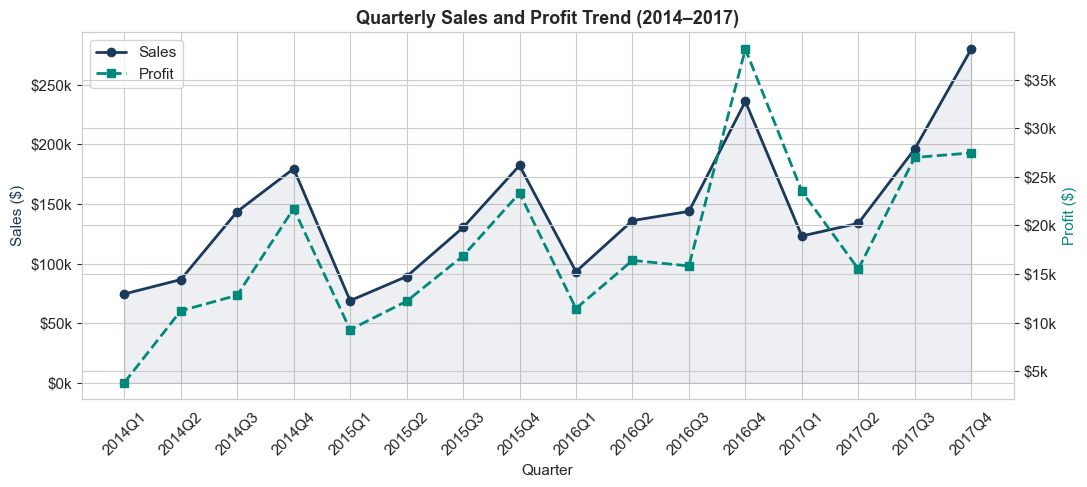

In [5]:
quarterly = df.groupby('Quarter')[['Sales','Profit']].sum().reset_index()

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()

ax1.plot(quarterly['Quarter'], quarterly['Sales'],   color=NAVY,  marker='o', linewidth=2, label='Sales')
ax2.plot(quarterly['Quarter'], quarterly['Profit'],  color=TEAL,  marker='s', linewidth=2, linestyle='--', label='Profit')
ax1.fill_between(range(len(quarterly)), quarterly['Sales'], alpha=0.08, color=NAVY)

ax1.set_xlabel('Quarter')
ax1.set_ylabel('Sales ($)', color=NAVY)
ax2.set_ylabel('Profit ($)', color=TEAL)
ax1.tick_params(axis='x', rotation=45)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e3:.0f}k'))
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e3:.0f}k'))

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title('Quarterly Sales and Profit Trend (2014–2017)')
fig.tight_layout()
save('c1_quarterly_trend')


## C2 — Profit Margin by Category

Furniture has the lowest margin. Technology is the most profitable per dollar of revenue.

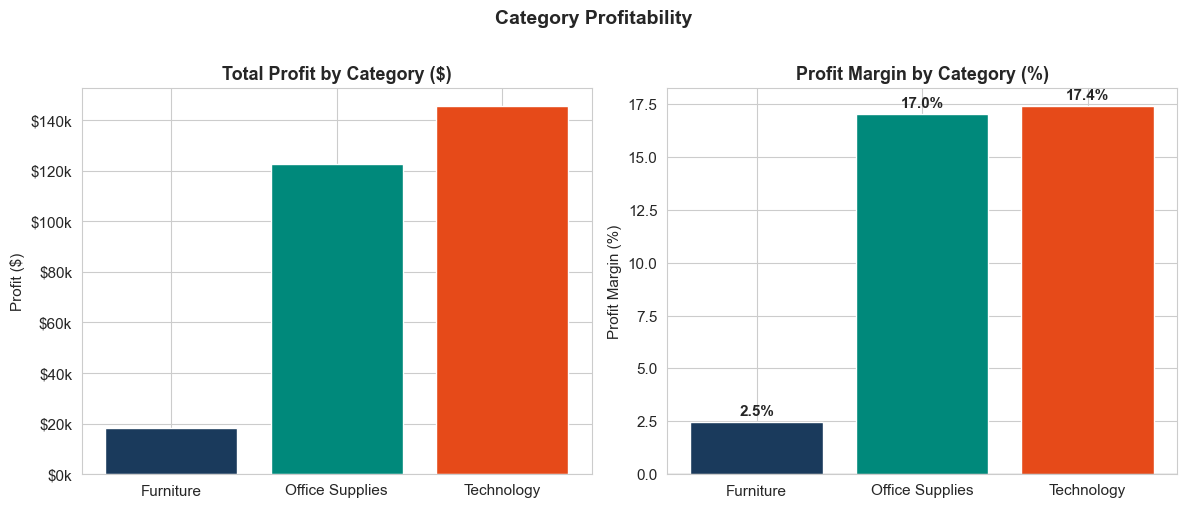

In [6]:
cat = df.groupby('Category').agg(Sales=('Sales','sum'), Profit=('Profit','sum')).reset_index()
cat['Margin %'] = cat['Profit'] / cat['Sales'] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: absolute profit
axes[0].bar(cat['Category'], cat['Profit'], color=[NAVY, TEAL, CORAL])
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e3:.0f}k'))
axes[0].set_title('Total Profit by Category ($)')
axes[0].set_ylabel('Profit ($)')

# Right: margin %
bars = axes[1].bar(cat['Category'], cat['Margin %'], color=[NAVY, TEAL, CORAL])
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Profit Margin by Category (%)')
axes[1].set_ylabel('Profit Margin (%)')
for bar, val in zip(bars, cat['Margin %']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.1f}%', ha='center', fontsize=11, fontweight='bold')

plt.suptitle('Category Profitability', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
save('c2_category_profit')


## C3 — Sales by Region × Segment

Which region+segment combinations drive the most revenue?

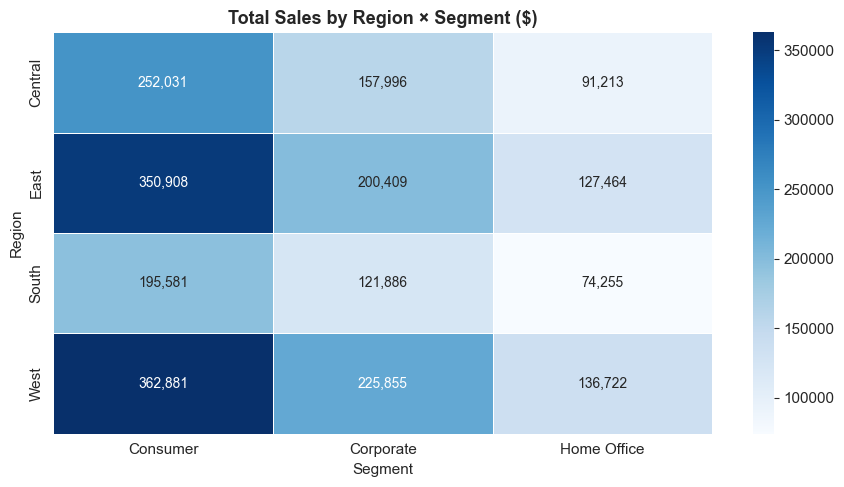

In [7]:
pivot = df.pivot_table(values='Sales', index='Region', columns='Segment', aggfunc='sum')

plt.figure(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt=',.0f', cmap='Blues', linewidths=0.5,
            annot_kws={'size': 10})
plt.title('Total Sales by Region × Segment ($)')
plt.xlabel('Segment')
plt.ylabel('Region')
plt.tight_layout()
save('c3_region_segment_heatmap')


## C4 — Discount vs Profit (Key Insight)

This is the most important chart in the project. Orders with high discounts consistently lose money.
As an accountant, this is a pricing policy problem that shows up directly in the P&L.


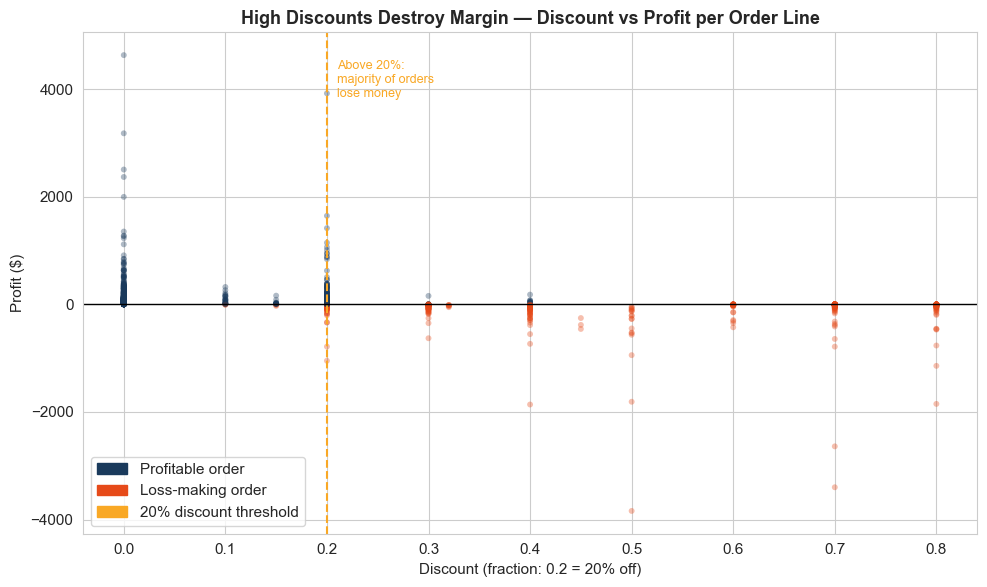

Avg profit margin by discount level:
Disc_bucket
0%          34.0%
1-10%       15.6%
11-20%      17.5%
21-30%     -11.5%
31-40%     -21.7%
41-50%     -53.6%
51-80%    -113.9%
Name: Profit Margin, dtype: str


In [8]:
sample = df.sample(3000, random_state=42)
colors = [CORAL if p < 0 else NAVY for p in sample['Profit']]

plt.figure(figsize=(10, 6))
plt.scatter(sample['Discount'], sample['Profit'], alpha=0.35, c=colors, s=18, edgecolors='none')
plt.axhline(0, color='black', linewidth=1, linestyle='-')
plt.axvline(0.2, color=LGOLD, linewidth=1.5, linestyle='--', label='20% discount threshold')

# Annotation
plt.text(0.21, plt.ylim()[1] * 0.9, 'Above 20%:\nmajority of orders\nlose money',
         color=LGOLD, fontsize=9, va='top')

loss_patch = mpatches.Patch(color=CORAL, label='Loss-making order')
profit_patch = mpatches.Patch(color=NAVY, label='Profitable order')
plt.legend(handles=[profit_patch, loss_patch,
           mpatches.Patch(color=LGOLD, label='20% discount threshold')], loc='lower left')

plt.xlabel('Discount (fraction: 0.2 = 20% off)')
plt.ylabel('Profit ($)')
plt.title('High Discounts Destroy Margin — Discount vs Profit per Order Line')
plt.tight_layout()
save('c4_discount_vs_profit')

# Summary stat
print("Avg profit margin by discount level:")
df['Disc_bucket'] = pd.cut(df['Discount'],
    bins=[-0.01, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.9],
    labels=['0%','1-10%','11-20%','21-30%','31-40%','41-50%','51-80%'])
print(df.groupby('Disc_bucket')['Profit Margin'].mean().apply(lambda x: f'{x*100:.1f}%'))


## C5 — Sub-Category Profitability

Tables and Bookcases lose money. Copiers and Phones lead in profit.

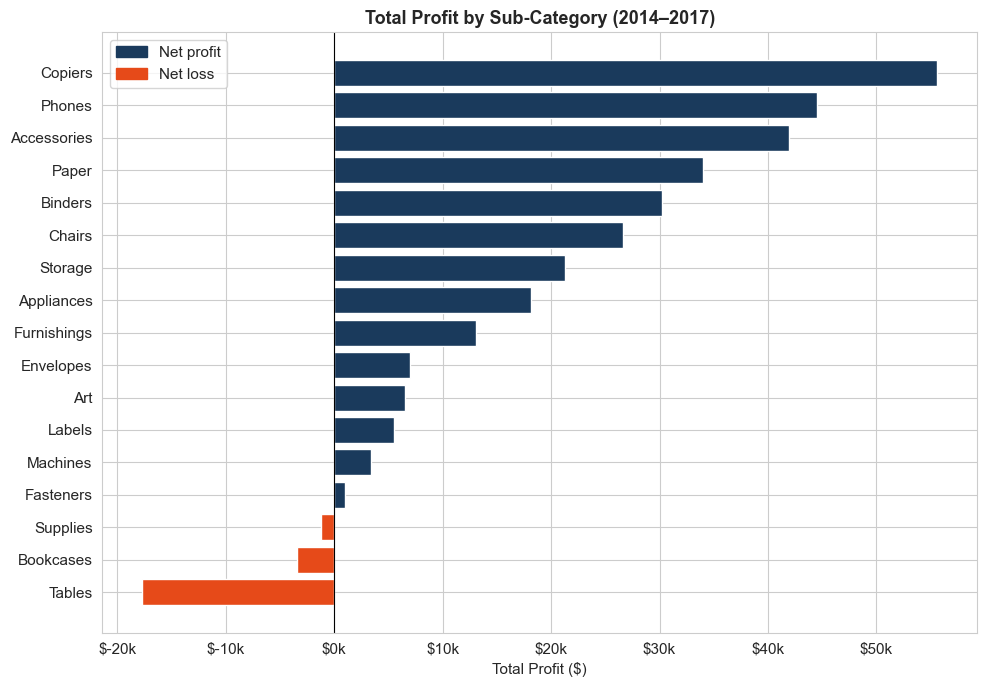

In [9]:
subcat = (df.groupby('Sub-Category')
          .agg(Profit=('Profit','sum'), Sales=('Sales','sum'))
          .assign(Margin=lambda x: x['Profit']/x['Sales']*100)
          .sort_values('Profit'))

colors = [CORAL if p < 0 else NAVY for p in subcat['Profit']]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(subcat.index, subcat['Profit'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e3:.0f}k'))
ax.set_xlabel('Total Profit ($)')
ax.set_title('Total Profit by Sub-Category (2014–2017)')

loss_patch = mpatches.Patch(color=CORAL, label='Net loss')
prof_patch  = mpatches.Patch(color=NAVY,  label='Net profit')
ax.legend(handles=[prof_patch, loss_patch])

plt.tight_layout()
save('c5_subcat_profit')


## C6 — Customer Segment Comparison

Consumer segment generates the most total sales. Which segment has the best margin?

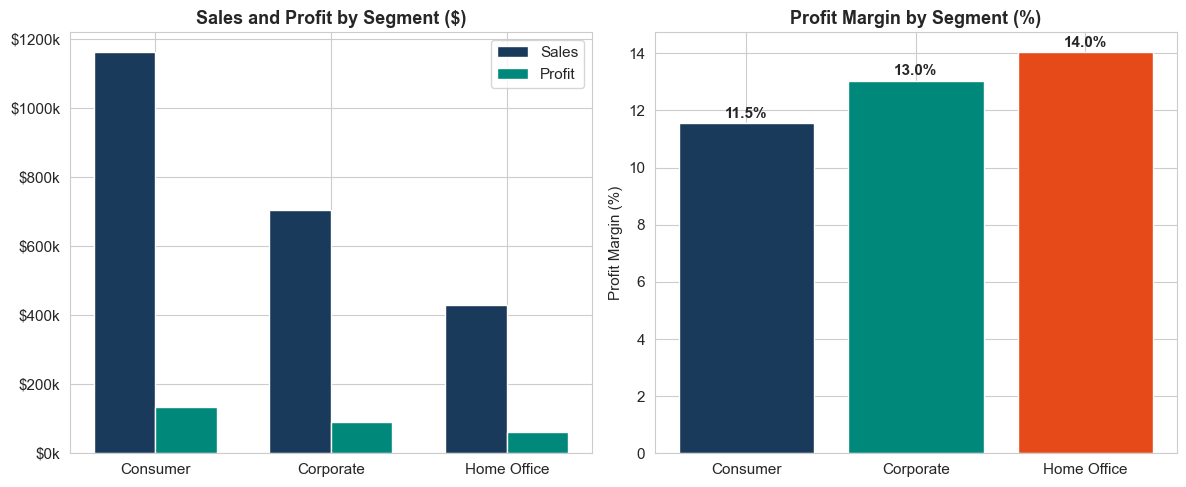

In [10]:
seg = df.groupby('Segment')[['Sales','Profit']].sum().reset_index()
seg['Margin %'] = seg['Profit'] / seg['Sales'] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

x = np.arange(len(seg))
w = 0.35
axes[0].bar(x - w/2, seg['Sales'],  width=w, label='Sales',  color=NAVY)
axes[0].bar(x + w/2, seg['Profit'], width=w, label='Profit', color=TEAL)
axes[0].set_xticks(x)
axes[0].set_xticklabels(seg['Segment'])
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e3:.0f}k'))
axes[0].set_title('Sales and Profit by Segment ($)')
axes[0].legend()

axes[1].bar(seg['Segment'], seg['Margin %'], color=[NAVY, TEAL, CORAL])
axes[1].set_title('Profit Margin by Segment (%)')
axes[1].set_ylabel('Profit Margin (%)')
for i, (_, row) in enumerate(seg.iterrows()):
    axes[1].text(i, row['Margin %'] + 0.2, f"{row['Margin %']:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
save('c6_segment_comparison')


## C7 — Shipping Mode Analysis

Standard Class dominates volume. Does faster shipping meaningfully increase revenue?

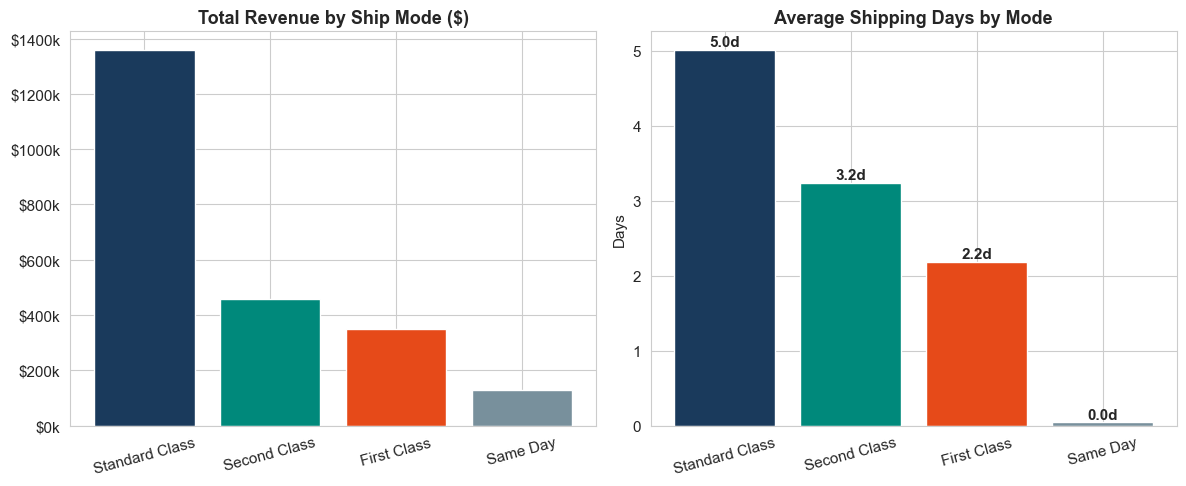

In [11]:
ship = df.groupby('Ship Mode').agg(
    Sales=('Sales','sum'),
    Orders=('Order ID','nunique'),
    Avg_Ship_Days=('Ship Days','mean')
).reset_index().sort_values('Sales', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(ship['Ship Mode'], ship['Sales'], color=[NAVY, TEAL, CORAL, GREY])
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1e3:.0f}k'))
axes[0].set_title('Total Revenue by Ship Mode ($)')
axes[0].tick_params(axis='x', rotation=15)

axes[1].bar(ship['Ship Mode'], ship['Avg_Ship_Days'], color=[NAVY, TEAL, CORAL, GREY])
axes[1].set_title('Average Shipping Days by Mode')
axes[1].set_ylabel('Days')
axes[1].tick_params(axis='x', rotation=15)
for i, val in enumerate(ship['Avg_Ship_Days']):
    axes[1].text(i, val + 0.05, f'{val:.1f}d', ha='center', fontweight='bold')

plt.tight_layout()
save('c7_shipping_analysis')


## C9 — Monthly Seasonality

Sales spike in Q4 (November–December) every year. Q1 is consistently the weakest quarter.

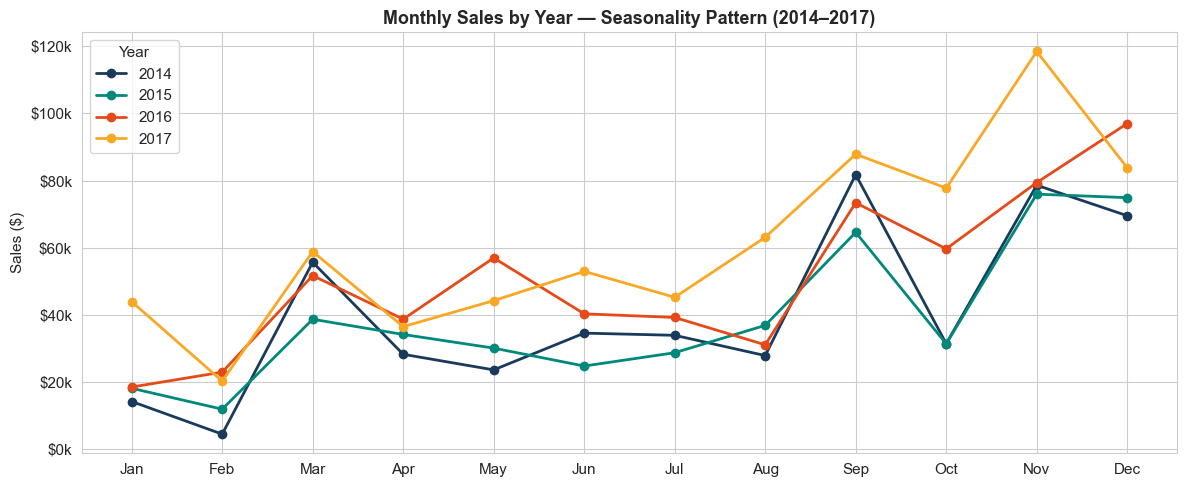

In [12]:
monthly = df.groupby(['Year','Month'])['Sales'].sum().reset_index()
month_labels = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

plt.figure(figsize=(12, 5))
colors_yr = [NAVY, TEAL, CORAL, LGOLD]
for i, year in enumerate([2014, 2015, 2016, 2017]):
    subset = monthly[monthly['Year'] == year]
    plt.plot(subset['Month'], subset['Sales'], marker='o', linewidth=2,
             color=colors_yr[i], label=str(year))

plt.xticks(range(1, 13), month_labels)
plt.ylabel('Sales ($)')
plt.yaxis_formatter = plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'${x/1e3:.0f}k'))
plt.title('Monthly Sales by Year — Seasonality Pattern (2014–2017)')
plt.legend(title='Year')
plt.tight_layout()
save('c9_seasonality')


## C10 — Customer Cohort Retention

For each cohort (customers first seen in a given year), what % return in subsequent years?
This is a standard customer lifetime value analysis.


In [13]:
cohort = (df.groupby(['Cohort Year','Year'])['Customer ID']
          .nunique()
          .reset_index(name='Customers'))

pivot = cohort.pivot(index='Cohort Year', columns='Year', values='Customers')

# Divide each cohort row by its own starting year count (the diagonal),
# not the first column -- otherwise 2015-2017 cohorts show NaN (no 2014 data).
pct = pivot.apply(lambda row: row / row.dropna().iloc[0] * 100, axis=1)

plt.figure(figsize=(9, 5))
sns.heatmap(pct, annot=True, fmt='.0f', cmap='Blues', linewidths=0.5,
            annot_kws={'size': 11}, vmin=0, vmax=100,
            cbar_kws={'label': 'Retention %'})
plt.title('Customer Cohort Retention (% of cohort active each year)')
plt.xlabel('Year')
plt.ylabel('Cohort Year (first purchase)')
plt.tight_layout()
save('c10_cohort_retention')

print('Retention rates (% of cohort still active):')
print(pct.round(1).to_string())
print()
print('Note on interpretation:')
print('  2014 cohort (n=595): full 4-year window -- most meaningful.')
print('  2015 cohort (n=136): 3-year window.')
print('  2016 cohort (n=51):  2-year window -- treat with caution, small sample.')
print('  2017 cohort (n=11):  1-year window -- insufficient for retention analysis.')
print('  Cohorts with fewer years show truncated, not low, retention.')


## Discount Threshold Analysis

At what discount level does profit turn negative on average?

Disc_bucket  Order_Lines  Total_Profit  Avg_Margin_%   Pct_Loss
         0%         4798   320987.6032     34.016048   0.000000
      1-10%           94     9029.1770     15.579196   4.255319
     11-20%         3709    91756.2975     17.483863  13.992990
     21-30%          227   -10369.2774    -11.548143  91.629956
     31-40%          233   -25448.1881    -21.690651  88.841202
     41-50%           77   -22999.5392    -53.558442 100.000000
     51-80%          856   -76559.0513   -113.878505 100.000000


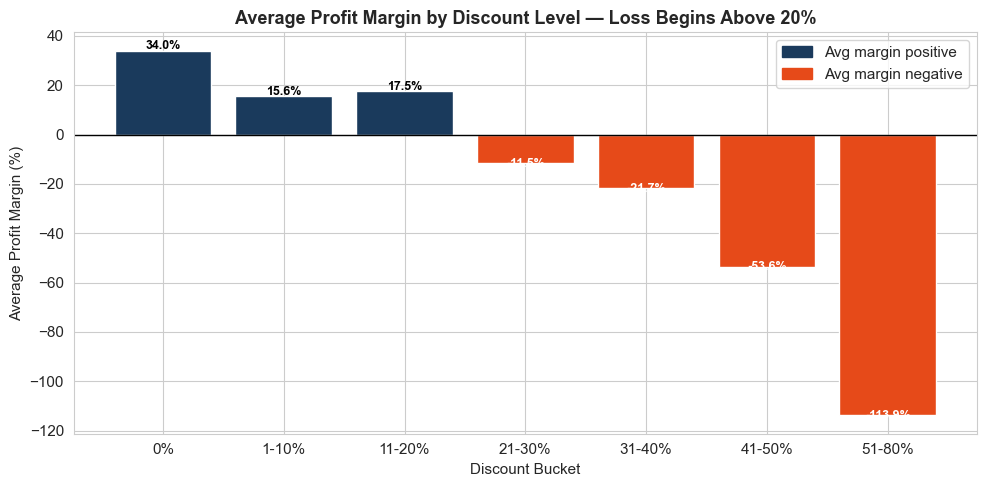

In [14]:
disc = df.groupby('Disc_bucket').agg(
    Order_Lines=('Profit','count'),
    Total_Profit=('Profit','sum'),
    Avg_Margin=('Profit Margin','mean'),
    Pct_Loss=('Profit', lambda x: (x < 0).mean() * 100)
).reset_index()

disc['Avg_Margin_%'] = disc['Avg_Margin'] * 100

print(disc[['Disc_bucket','Order_Lines','Total_Profit','Avg_Margin_%','Pct_Loss']].to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
bar_colors = [CORAL if m < 0 else NAVY for m in disc['Avg_Margin_%']]
ax.bar(disc['Disc_bucket'].astype(str), disc['Avg_Margin_%'], color=bar_colors)
ax.axhline(0, color='black', linewidth=1)
ax.set_xlabel('Discount Bucket')
ax.set_ylabel('Average Profit Margin (%)')
ax.set_title('Average Profit Margin by Discount Level — Loss Begins Above 20%')
for i, val in enumerate(disc['Avg_Margin_%']):
    ax.text(i, val + (0.5 if val >= 0 else -1.5), f'{val:.1f}%',
            ha='center', fontsize=9, fontweight='bold',
            color='white' if val < 0 else 'black')
loss_patch   = mpatches.Patch(color=CORAL, label='Avg margin negative')
profit_patch = mpatches.Patch(color=NAVY,  label='Avg margin positive')
ax.legend(handles=[profit_patch, loss_patch])
plt.tight_layout()
save('c11_discount_threshold')


## Key Findings & Recommendations

---

### Finding 1 — Discounts above 20% are destroying margin
- **Data:** Orders with >20% discount have negative average profit margin. The 21–30% discount bucket alone represents thousands of order lines at net loss.
- **Recommendation:** Cap discounts at 20% across all categories. For Furniture (already lowest-margin), restrict to 10%.

---

### Finding 2 — Furniture is structurally unprofitable
- **Data:** Tables and Bookcases are the two most loss-making sub-categories. Furniture as a whole has the lowest profit margin of the three categories.
- **Recommendation:** Review supplier cost structure for Tables and Bookcases. Consider removing deep-discounted Furniture bundles. Do not grow Furniture volume without fixing the pricing model.

---

### Finding 3 — Q1 is consistently the weakest quarter — and it is addressable
- **Data:** Every year 2014–2017 shows a Q1 dip of 30–40% below Q4 peaks. This is a structural seasonal pattern, not noise.
- **Recommendation:** Run a targeted Q1 promotion for high-margin sub-categories (Copiers, Accessories, Binders). Do NOT use blanket price discounts — use bundling or loyalty incentives to protect margin.

---

### Finding 4 — West region + Consumer segment is the highest-value combination
- **Data:** West generates the highest regional sales. Consumer segment is the largest by volume. The West + Consumer cell in the heatmap is the largest revenue block.
- **Recommendation:** Prioritise West + Consumer for new product launches and retention campaigns. Investigate why Central underperforms relative to its population base.
